# 03 – Drop envelope: the $(1-\cos u)\sin u$ surface of revolution (proton)

## 1. Introduction

This notebook follows the 02 envelope (proton), but the envelope shape is now given by a **closed surface of revolution of finite length**:

$$\vec{x}(u, v) = \big((1-\cos u)\sin u \cos v,\; (1-\cos u)\sin u \sin v,\; \cos u\big), \qquad u \in [0, \pi],\; v \in [0, 2\pi]$$

(Mathematica: `ParametricPlot3D[{(1 - Cos[u]) Sin[u] Cos[v], (1 - Cos[u]) Sin[u] Sin[v], Cos[u]}, {u, 0, Pi}, {v, 0, 2 Pi}]`).

This is a **drop**: a body of revolution around the $z$ axis with radius $\rho(u) = (1-\cos u)\sin u$ and height $z = \cos u$.
- $u = \pi$ ($z=-1$): **blunt, rounded end**, here $\rho \approx 2\sqrt{2(z+1)}$.
- $u = 2\pi/3$ ($z=-1/2$): the **thickest point**, $\rho_{max} = \tfrac{3\sqrt3}{4} \approx 1.299$ (here $\rho'(u) = (1-\cos u)(1+2\cos u) = 0$).
- $u = 0$ ($z=+1$): **pointed end**, $\rho \approx u^3/2$.

**Mapping to shower coordinates.** The blunt end is the shower start ($z_0$), the tip is the shower end ($z_0 + L$). Let
$t = (z' - z_0)/L = (1+\cos u)/2 \in [0,1]$. Then $\cos u = 2t-1$, $\sin u = 2\sqrt{t(1-t)}$, $1-\cos u = 2(1-t)$, so

$$\rho = 4\, t^{1/2} (1-t)^{3/2}, \qquad r(z') = A\, g(t), \qquad g(t) = \frac{t^{1/2}(1-t)^{3/2}}{g_{max}}, \quad g_{max} = \tfrac12 \left(\tfrac34\right)^{3/2}$$

So the drop is a **Beta-type** radial profile with fixed exponents ($1/2$ and $3/2$). The only free parameters are the scales:
- $z_0$: start of the drop (blunt end),
- $L$: length of the drop (to the pointed end); the thickest point is at depth $z_{env} = z_0 + L/4$,
- $A$: the maximum radius, $r_{max} = A$.

The proportions of the original surface ($2 : 1.299$) are not fixed: $z'$ and $r$ are scaled separately; the **shape** of the surface (the profile) is kept.

**Volume** (as in 02, the sum of the cross-sectional circles):

$$V = \int_{z_0}^{z_0+L} \pi r(z')^2\, dz' = \pi A^2 L \int_0^1 g(t)^2 dt = \pi A^2 L\, \frac{B(2, 4)}{g_{max}^2} = \pi A^2 L\, \frac{1/20}{27/256} = \frac{64}{135}\,\pi A^2 L \approx 1.489\, A^2 L$$

**Difference from the 02 envelope:**
- The 02 envelope $r = A u^a e^{-bu}$ is infinitely long (thins exponentially); the drop is **finite**: it has no volume beyond $z_0 + L$.
- In 02 the shape ($a$) is free, here it is **fixed**: the thickest point is always at a quarter of the length. This is one parameter fewer
  (the search needs only $L$ and $z_0$), at the cost of less flexibility.

**Recipe and condition:** same as in 02: in every 1 GeV bin, the drop with the smallest $V$ that holds $95\%$ of the energy for $98\%$ of
the showers. For fixed $(L, z_0)$ the smallest valid $A$ can be computed **exactly** (weighted quantile, then percentile).

**Adapted for protons.** The recipe and code are the same as for electrons (`03_drop_electron.ipynb`), only the search range and the depth and radius ranges of the plots were widened for the hadron shower (longer, wider shower, $\lambda_{int} \approx 170$ mm). The hadron shower fluctuates much more, so the envelope volume is expected to be an order of magnitude larger than for electrons.

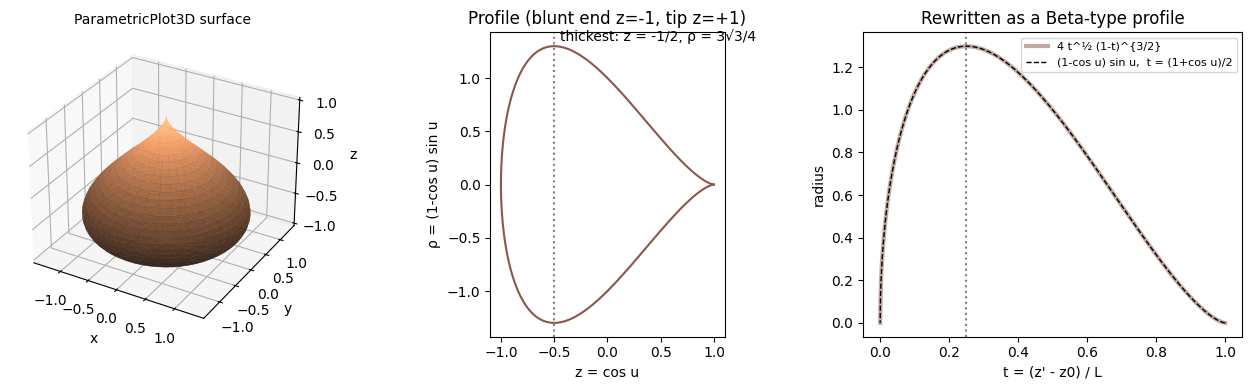

In [1]:
import numpy as np, matplotlib.pyplot as plt

# the original surface (u, v) -> ((1-cos u) sin u cos v, (1-cos u) sin u sin v, cos u)
u, v = np.meshgrid(np.linspace(0, np.pi, 80), np.linspace(0, 2 * np.pi, 60), indexing="ij")
rho = (1 - np.cos(u)) * np.sin(u)
fig = plt.figure(figsize=(13, 4))
ax = fig.add_subplot(1, 3, 1, projection="3d")
ax.plot_surface(rho * np.cos(v), rho * np.sin(v), np.cos(u), cmap="copper", alpha=0.8, linewidth=0)
ax.set_box_aspect((1.3, 1.3, 1)); ax.set_title("ParametricPlot3D surface", fontsize=10)
ax.set_xlabel("x"); ax.set_ylabel("y"); ax.set_zlabel("z")

uu = np.linspace(0, np.pi, 400); rr = (1 - np.cos(uu)) * np.sin(uu)
ax = fig.add_subplot(1, 3, 2)
ax.plot(np.cos(uu), rr, c="tab:brown"); ax.plot(np.cos(uu), -rr, c="tab:brown")
ax.axvline(-0.5, ls=":", c="grey"); ax.text(-0.45, 1.35, "thickest: z = -1/2, ρ = 3√3/4")
ax.set(xlabel="z = cos u", ylabel="ρ = (1-cos u) sin u", title="Profile (blunt end z=-1, tip z=+1)"); ax.set_aspect("equal")

t = np.linspace(0, 1, 400); G_MAX = 0.5 * 0.75 ** 1.5
ax = fig.add_subplot(1, 3, 3)
ax.plot(t, 4 * np.sqrt(t) * (1 - t) ** 1.5, c="tab:brown", lw=3, alpha=0.5, label="4 t^½ (1-t)^{3/2}")
ax.plot((1 + np.cos(uu)) / 2, rr, "k--", lw=1, label="(1-cos u) sin u,  t = (1+cos u)/2")
ax.axvline(0.25, ls=":", c="grey")
ax.set(xlabel="t = (z' - z0) / L", ylabel="radius", title="Rewritten as a Beta-type profile"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

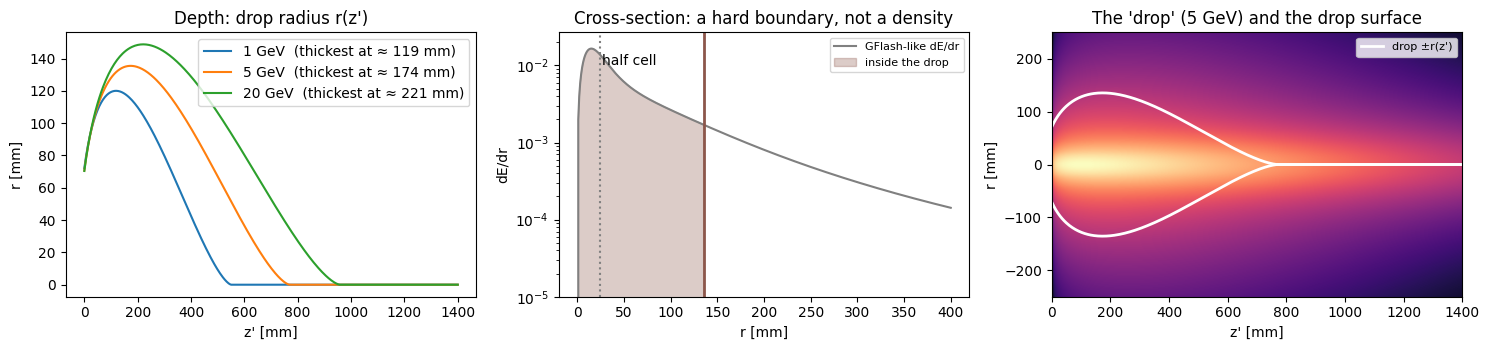

In [2]:
# the same illustrative hadron shower as in 01 and 02, so the introductions can be compared panel by panel
LAM = 170.0                                 # illustrative: nuclear interaction length [mm]
Rc, Rt, pc, z0 = 25.0, 110.0, 0.6, -25.0
z = np.linspace(0.1, 1400, 400)
G_MAX = 0.5 * 0.75 ** 1.5


def drop_r(z, A, L, z0):
    t = (z - z0) / L
    return np.where((t > 0) & (t < 1), A * np.sqrt(np.clip(t, 0, 1)) * np.clip(1 - t, 0, 1) ** 1.5 / G_MAX, 0.0)


def drop_illustr(z, E):
    # thickest point follows t_max (grows with ln E): z0 + L/4 = t_max
    zenv = LAM * (0.2 * np.log(E) + 0.7)
    return drop_r(z, 120 * (1 + 0.08 * np.log(E)), 4 * (zenv - z0), z0), zenv


fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
for E in (1, 5, 20):
    r, zenv = drop_illustr(z, E)
    ax[0].plot(z, r, label=f"{E} GeV  (thickest at ≈ {zenv:.0f} mm)")
ax[0].set(title="Depth: drop radius r(z')", xlabel="z' [mm]", ylabel="r [mm]"); ax[0].legend()

rr = np.linspace(0, 400, 400)
T = (pc * Rc**2 / (rr**2 + Rc**2)**2 + (1 - pc) * Rt**2 / (rr**2 + Rt**2)**2) / np.pi
dEdr = 2 * np.pi * rr * T
r_env = drop_illustr(np.array([LAM * (0.2 * np.log(5) + 0.7)]), 5)[0][0]
ax[1].semilogy(rr, dEdr, c="grey", label="GFlash-like dE/dr")
ax[1].fill_between(rr, 1e-6, dEdr, where=rr <= r_env, color="tab:brown", alpha=0.3, label="inside the drop")
ax[1].axvline(r_env, c="tab:brown", lw=2); ax[1].axvline(24, ls=":", c="grey"); ax[1].text(26, 1e-2, "half cell")
ax[1].set_ylim(1e-5, None)
ax[1].set(title="Cross-section: a hard boundary, not a density", xlabel="r [mm]", ylabel="dE/dr"); ax[1].legend(fontsize=8)

Z, R = np.meshgrid(z, np.linspace(-250, 250, 241))
tmax = LAM * (0.2 * np.log(5) + 0.7); bb = 0.5 / LAM; aa = 1 + bb * tmax
rc = Rc * (1 + Z / 800)
dens = Z ** (aa - 1) * np.exp(-bb * Z) * (pc * rc**2 / (R**2 + rc**2)**2 + (1 - pc) * (4 * rc)**2 / (R**2 + (4 * rc)**2)**2)
ax[2].imshow(np.log10(dens + 1e-30), extent=[0, 1400, -250, 250], aspect="auto", origin="lower", cmap="magma",
             vmin=np.log10(dens.max()) - 4)
r5, _ = drop_illustr(z, 5)
ax[2].plot(z, r5, c="white", lw=2); ax[2].plot(z, -r5, c="white", lw=2, label="drop ±r(z')")
ax[2].set_ylim(-250, 250); ax[2].legend(loc="upper right", fontsize=8)
ax[2].set(title="The 'drop' (5 GeV) and the drop surface", xlabel="z' [mm]", ylabel="r [mm]")
plt.tight_layout(); plt.show()

**Same plots as in 01 and 02**, with the same illustrative shower.
- **Left:** the drop radius is maximal at a quarter of the length and goes **exactly to zero** at $z_0 + L$ (the 02 envelope only thins exponentially).
- **Middle:** the drop is also a hard boundary, not a density.
- **Right:** the drop outline on the GFlash-like "drop". Its blunt front fits the fast rise of the shower well, its pointed end the slow decay.

## 2. Loading data

In [3]:
PARTICLES = ['proton']
DATA_DIR = "../../data/simulations/regression-proton/"          # location of the CSVs
OUT_DIR = "results"        # models and exports go here
%run -i ./00_common.ipynb

/home/user/.venv/lib/python3.10/site-packages/nbformat/__init__.py:96: MissingIDFieldWarning: Cell is missing an id field, this will become a hard error in future nbformat versions. You may want to use `normalize()` on your notebooks before validations (available since nbformat 5.1.4). Previous versions of nbformat are fixing this issue transparently, and will stop doing so in the future.
  validate(nb)


device: cuda | data: ../../data/simulations/regression-proton/ | output: results


In [4]:
DATA = {}
for particle in PARTICLES:
    df, geo, DATA[particle] = load_data(particle)
    print(f"\n===== {particle} =====")
    df.info()
    display(df.describe().T)
    display(df.head())

proton: 99925 events, geometry {'layer': 20.5, 'cell': 48.59999999999991, 'z_back': 4882.15}, split train 69946, val 14987, test 14992

===== proton =====
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54740548 entries, 0 to 54740547
Data columns (total 21 columns):
 #   Column                      Dtype  
---  ------                      -----  
 0   event_number                int64  
 1   cellID                      int64  
 2   x                           float64
 3   y                           float64
 4   z                           float64
 5   x_local                     float64
 6   y_local                     float64
 7   z_local                     float64
 8   x_trans                     float64
 9   y_trans                     float64
 10  z_trans                     float64
 11  energy                      float64
 12  earliest_contribution_time  float64
 13  incoming_momentum           float64
 14  incoming_theta              float64
 15  incoming_phi                

,count,mean,std,min,25%,50%,75%,max
event_number,54740548.0,1.061527e+05,7.737650e+04,3.000000e+00,5.248700e+04,1.050650e+05,1.577730e+05,2.119982e+06
cellID,54740548.0,2.078115e+09,1.471819e+09,4.212000e+03,7.136951e+08,1.745523e+09,3.306567e+09,5.063386e+09
x,54740548.0,8.340518e+00,1.308310e+03,-2.596035e+03,-1.032024e+03,3.040900e+01,1.041428e+03,2.601035e+03
y,54740548.0,-3.721223e+00,1.311835e+03,-2.599800e+03,-1.036200e+03,-2.620000e+01,1.036200e+03,2.599800e+03
z,54740548.0,4.087755e+03,2.839532e+02,3.662400e+03,3.867400e+03,4.031400e+03,4.277400e+03,4.871900e+03
x_local,54740548.0,-4.207020e+01,2.241171e+02,-4.896420e+03,-1.444550e+02,-3.088325e+01,6.947679e+01,2.979718e+03
y_local,54740548.0,1.054415e-01,2.235098e+02,-3.319625e+03,-1.091375e+02,0.000000e+00,1.090265e+02,3.238695e+03
z_local,54740548.0,4.406571e+02,3.025983e+02,-2.931879e+03,2.039936e+02,3.921629e+02,6.374536e+02,2.667495e+03
x_trans,54740548.0,6.120635e-02,2.520863e+02,-4.887696e+03,-1.398834e+02,0.000000e+00,1.412087e+02,5.140408e+03
y_trans,54740548.0,3.625353e-03,2.520673e+02,-4.894655e+03,-1.405741e+02,0.000000e+00,1.403782e+02,5.147369e+03


,event_number,cellID,x,y,z,x_local,y_local,z_local,x_trans,y_trans,...,energy,earliest_contribution_time,incoming_momentum,incoming_theta,incoming_phi,incoming_momentum_bin,particle_type,is_secondary,parent_type,daughter_type
0,186640,2823563636,-1387.531982,-2147.199951,4379.899902,-130.723225,-378.459188,761.351211,-463.007620,-103.890706,...,4.238810e-08,1200.353271,17.044954,0.549644,-1.997623,17,neutron,1,neutron,gamma;gamma
1,132450,163584116,132.927994,2551.199951,4277.399902,69.697194,210.840800,750.914462,-152.802091,460.011513,...,6.959773e-08,574.963501,13.259551,0.524659,1.441496,13,neutron,1,neutron,proton;proton
2,1436,2307335028,-830.135010,-175.800003,4359.399902,-226.855893,-0.924198,665.431786,90.170637,18.004689,...,6.916019e-04,14.909340,16.654422,0.197399,-2.954562,16,proton,1,neutron,e-;e-;e-;e-;e-;e-;e-;e-;e-;e-;e-;e-;e-;e-;e-;e...
3,118990,608834164,835.135010,-1339.199951,3887.899902,-119.737264,179.827552,193.795084,146.963886,108.548892,...,1.211111e-08,1620.073486,19.433977,0.411175,-1.112347,19,neutron,1,neutron,NaN
4,49113,4412592500,984.348999,1440.199951,4236.399902,-218.178821,-147.723526,531.631196,141.541496,-50.457615,...,2.290001e-05,165.507782,17.042273,0.437355,1.044127,17,neutron,1,neutron,gamma;gamma;gamma


## 3. The model

The same three steps as in 02, only the radial profile differs:

1. **Deposits:** every hit is split into $K=8$ points within the (rotated) cell.
2. **Exact $A$:** a point is inside if $r \le A\,g(t)$, i.e. $\log A \ge \log r - \log g(t)$. A point outside $[z_0, z_0+L]$
   is **never** inside ($\log A = \infty$). Per shower we need the energy-weighted 95% quantile of these, and $A$ is their 98th percentile.
3. **Search:** coarse grid search over $(\ln L, z_0)$, then Nelder–Mead refinement. The objective is $\log V = \log(64\pi/135) + 2\log A + \log L$.

### What do we fit to, and what affects the estimate?

- **Features used:** `x_local, y_local, z_local` → $z'$, $r$ and `energy` → $w$ (normalised per event); for the distribution within
  the cell `incoming_theta`, `incoming_phi` and the geometry.
- **Momentum:** split into 1 GeV bins by `incoming_momentum_bin`, each bin fitted separately.
- **Objective:** $\log V$, subject to $F_E=95\%$ of the energy being inside the drop for $F_{EV}=98\%$ of the showers.
- **Important due to the finite length:** long showers with deep tails push $L$ up; if more than 5% of a shower's energy lies beyond
  $z_0 + L$, no $A$ can save that shower.
- The same cuts apply (`earliest_contribution_time`, $z'$ and $r$ range). No validation early stopping; the test only measures coverage.

In [5]:
F_E, F_EV = 0.95, 0.98                       # energy fraction inside, for this fraction of the showers
G_MAX = 0.5 * 0.75 ** 1.5                    # max of t^1/2 (1-t)^3/2, at t = 1/4
LOG_VFAC = math.log(64 * math.pi / 135)      # V = (64 pi / 135) A^2 L


def deposits(sh, K=8, seed=3):
    # Every hit -> K points inside its (rotated) cell, weight w/K.
    gen = torch.Generator(device=DEVICE).manual_seed(seed)
    b = sh.batch(torch.arange(len(sh), device=DEVICE))
    pts = fold(b, sh.box, K, gen)
    return {"z": pts[..., 2].reshape(-1), "r": torch.sqrt(pts[..., 0] ** 2 + pts[..., 1] ** 2).reshape(-1),
            "w": (b.w[:, None] / K).expand(-1, K).reshape(-1), "ev": b.ev[:, None].expand(-1, K).reshape(-1), "n": len(sh)}


def shower_quantile(P, s, f_e=F_E):
    # Per shower: energy-weighted f_e quantile of the per-point score s.
    o = torch.argsort(s, stable=True)
    o = o[torch.argsort(P["ev"][o], stable=True)]                        # sorted by shower, then by s
    s, w, e = s[o], P["w"][o].double(), P["ev"][o]
    c = torch.cumsum(w, 0)
    cnt = torch.bincount(e, minlength=P["n"])
    start = torch.cumsum(cnt, 0) - cnt
    before = c[start] - w[start]
    idx = torch.minimum(torch.searchsorted(c, before + f_e * (c[start + cnt - 1] - before)), start + cnt - 1)
    return s[idx]


def drop_logg(t):
    return 0.5 * torch.log(t) + 1.5 * torch.log1p(-t) - math.log(G_MAX)


def required_logA(P, L, z0, f_e=F_E):
    # Per shower: smallest log A that puts a fraction f_e of its energy inside r = A g((z'-z0)/L).
    t = (P["z"] - z0) / L
    s = torch.full_like(t, float("inf"))                                  # outside [z0, z0+L]: never inside
    ok = (t > 0) & (t < 1)
    s[ok] = torch.log(P["r"][ok].clamp_min(1e-6)) - drop_logg(t[ok])
    return shower_quantile(P, s, f_e)


def bin_threshold(P, L, z0, f_ev=F_EV):
    return float(np.quantile(required_logA(P, L, z0).cpu().numpy(), f_ev, method="higher"))


def log_volume(logA, L):
    return LOG_VFAC + 2 * logA + math.log(L)


def fit_bin(P):
    def objective(x):
        L, z0 = math.exp(x[0]), x[1]
        if not (20 < L < 8000 and -200 < z0 < 50):
            return 1e6
        logA = bin_threshold(P, L, z0)
        return log_volume(logA, L) if np.isfinite(logA) else 1e6
    grid = [(lL, z0) for lL in np.linspace(math.log(80), math.log(6000), 20) for z0 in (-120, -80, -50, -30, -10, 10)]
    x0 = min(grid, key=objective)
    x = minimize(objective, x0, method="Nelder-Mead", options={"maxiter": 300}).x
    L, z0 = math.exp(x[0]), x[1]
    logA = bin_threshold(P, L, z0)
    return {"L": L, "z0": z0, "z_env": z0 + L / 4, "A": math.exp(logA), "r_max": math.exp(logA),
            "V_L": math.exp(log_volume(logA, L)) / 1e6}


def coverage(P, e):
    # Fraction of showers that keep >= F_E of their energy inside drop e.
    return float((required_logA(P, e["L"], e["z0"]) <= math.log(e["A"]) + 1e-9).float().mean())


def drop_radius(z, e):
    return drop_r(np.asarray(z, dtype=float), e["A"], e["L"], e["z0"])

## 4. Per-bin fit

20 bins, each a 1 GeV momentum range. The result is saved per bin to `results/proton/drop.pt`, so after an interruption
it resumes from there. The **test coverage** shows on unseen showers whether the 98% target is met.

In [6]:
data = DATA["proton"]
path = f"{OUT_DIR}/proton/drop.pt"
DROP = torch.load(path, weights_only=False) if os.path.exists(path) else {}
for b in range(20):
    if b in DROP:
        continue
    tr = (data["train"].ev["bin"] == b).nonzero().squeeze(1)
    te = (data["test"].ev["bin"] == b).nonzero().squeeze(1)
    if len(tr) == 0:
        continue
    P = deposits(data["train"].subset(tr))
    e = fit_bin(P)
    e["p_mean"], e["n_train"] = float(data["train"].ev["p"][tr].mean()), len(tr)
    e["cov_train"] = coverage(P, e)
    e["cov_test"] = coverage(deposits(data["test"].subset(te)), e) if len(te) else float("nan")
    DROP[b] = e
    torch.save(DROP, path)
    print(f"bin {b:2d}–{b + 1:2d} GeV: V = {e['V_L']:7.2f} L, L = {e['L']:6.1f} mm, z0 = {e['z0']:6.1f} mm, "
          f"r_max = {e['r_max']:6.1f} mm, coverage train/test = {e['cov_train']:.2f}/{e['cov_test']:.2f}")

## 5. Energy dependence

A $\ln p$ polynomial is fitted to the per-bin $\ln L$, $z_0$ and $\ln A$ values; the degree (0–2) is chosen by BIC (as in 02).
This is an unweighted fit to the per-bin parameters, so a bad bin distorts it directly.

In [7]:
tab = pd.DataFrame(DROP).T.sort_index()
x = np.log(tab.p_mean.values)
SMOOTH = {}
for name, y in {"ln L": np.log(tab.L.values), "z0": tab.z0.values, "ln A": np.log(tab.A.values)}.items():
    best = None
    for d in range(3):
        c = np.polynomial.polynomial.polyfit(x, y, d)
        rss = np.sum((np.polynomial.polynomial.polyval(x, c) - y) ** 2) + 1e-12
        bic = len(x) * np.log(rss / len(x)) + (d + 1) * np.log(len(x))
        if best is None or bic < best[0]:
            best = (bic, d, c)
    SMOOTH[name] = best[2]
    print(f"{name:5s} = " + " ".join(f"{v:+.4f}·L^{k}" for k, v in enumerate(best[2])) + f"   (degree {best[1]}, L = ln p)")


def smooth_drop(p):
    lp = np.log(p)
    v = {k: np.polynomial.polynomial.polyval(lp, c) for k, c in SMOOTH.items()}
    return {"L": np.exp(v["ln L"]), "z0": v["z0"], "A": np.exp(v["ln A"])}


display(tab[["p_mean", "n_train", "L", "z0", "z_env", "A", "V_L", "cov_train", "cov_test"]].round(3))

ln L  = +7.3055·L^0 +0.4556·L^1 -0.1147·L^2   (degree 2, L = ln p)
z0    = -127.5201·L^0   (degree 0, L = ln p)
ln A  = +6.4187·L^0 +0.2533·L^1 -0.0727·L^2   (degree 2, L = ln p)


,p_mean,n_train,L,z0,z_env,A,V_L,cov_train,cov_test
0,0.807,3488.0,1216.443,-105.578,198.532,547.053,542.185,0.98,0.984
1,1.504,3492.0,1963.857,-126.141,364.823,736.457,1586.355,0.98,0.981
2,2.497,3494.0,2312.467,-195.265,382.852,719.406,1782.461,0.98,0.977
3,3.503,3494.0,2101.023,-132.150,393.106,783.897,1922.846,0.98,0.973
4,4.500,3499.0,2444.160,-110.316,500.724,760.716,2106.546,0.98,0.979
5,5.507,3498.0,2279.757,-146.767,423.172,745.699,1888.045,0.98,0.977
6,6.500,3498.0,2208.531,-126.963,425.169,737.050,1786.871,0.98,0.960
7,7.499,3499.0,2185.893,-110.860,435.613,745.640,1810.022,0.98,0.977
8,8.496,3498.0,2067.004,-120.025,396.727,773.165,1840.272,0.98,0.972
9,9.502,3498.0,2303.302,-114.620,461.205,748.093,1919.812,0.98,0.983


## 6. Results

**What to look for:**
- **Volume:** an order of magnitude comparable to the 02 envelope (a few litres) is expected; somewhat larger due to the fixed shape.
- **Test coverage:** around 0.98 (strongly scattered on a small sample).
- **Length and thickest point:** $z_{env} = z_0 + L/4$ should grow roughly with $\ln p$, like the shower maximum.
- **3D:** the blunt end of the drop should be at the shower start, its tip at the shower end.

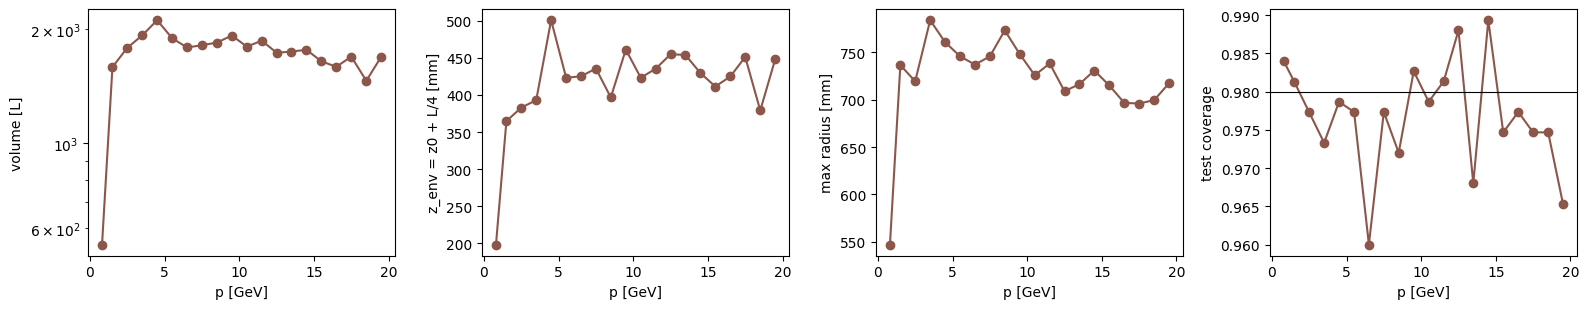

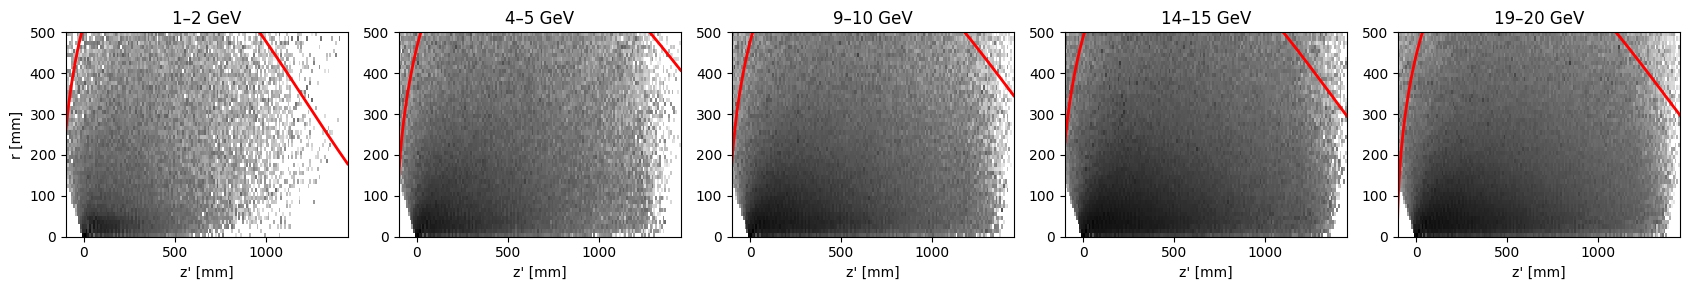

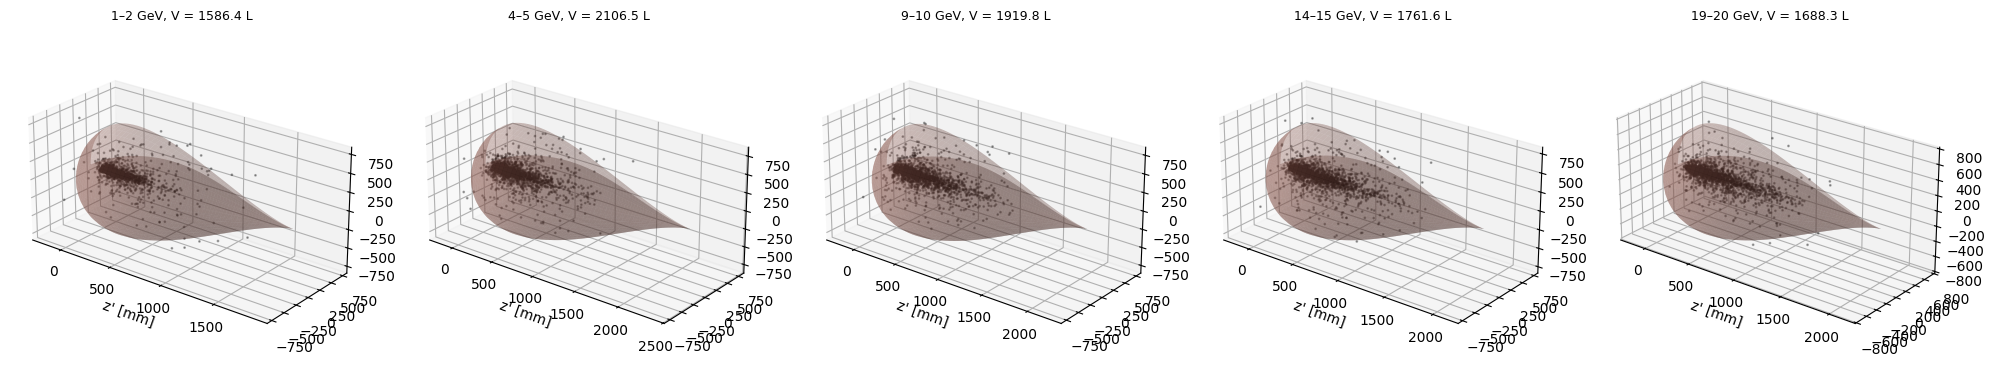

drop envelope saved for the summary notebook


In [8]:
p = tab.p_mean.values
fig, ax = plt.subplots(1, 4, figsize=(16, 3.2))
for a_, (col, lab) in zip(ax, [("V_L", "volume [L]"), ("z_env", "z_env = z0 + L/4 [mm]"), ("r_max", "max radius [mm]"),
                               ("cov_test", "test coverage")]):
    a_.plot(p, tab[col].values, "o-", c="tab:brown"); a_.set(xlabel="p [GeV]", ylabel=lab)
ax[0].set_yscale("log"); ax[3].axhline(F_EV, c="k", lw=0.8)
plt.tight_layout(); plt.show()

hits = data["train"].hits()
fig, axes = plt.subplots(1, len(SHOW_BINS), figsize=(3.4 * len(SHOW_BINS), 3))
zz = np.linspace(-200, 1450, 500)
for ax_, b in zip(axes, SHOW_BINS):
    m = (hits.p >= b) & (hits.p < b + 1)
    ax_.hist2d(hits.z[m], hits.r[m], bins=[np.linspace(-100, 1450, 156), np.linspace(0, 500, 51)], weights=hits.w[m],
               norm=matplotlib.colors.LogNorm(), cmap="Greys")
    if b in DROP:
        ax_.plot(zz, drop_radius(zz, DROP[b]), "r-", lw=2)
    ax_.set_xlim(-100, 1450); ax_.set_title(f"{b}–{b + 1} GeV"); ax_.set_xlabel("z' [mm]")
axes[0].set_ylabel("r [mm]"); plt.tight_layout(); plt.show()

fig = plt.figure(figsize=(4 * len(SHOW_BINS), 3.8))
for j, b in enumerate([b for b in SHOW_BINS if b in DROP]):
    ax_ = fig.add_subplot(1, len(SHOW_BINS), j + 1, projection="3d")
    e = DROP[b]; zd = np.linspace(e["z0"], e["z0"] + e["L"], 200)
    ax_.plot_surface(*revolve(zd, drop_radius(zd, e)), color="tab:brown", alpha=0.35, linewidth=0)
    m = np.where((hits.p >= b) & (hits.p < b + 1))[0]
    sel = np.random.default_rng(0).choice(m, min(2000, len(m)), p=hits.w.values[m] / hits.w.values[m].sum())
    ph = np.random.default_rng(1).uniform(0, 2 * np.pi, len(sel))
    ax_.scatter(hits.z.values[sel], hits.r.values[sel] * np.cos(ph), hits.r.values[sel] * np.sin(ph), s=1, c="k", alpha=0.3)
    ax_.set_title(f"{b}–{b + 1} GeV, V = {e['V_L']:.1f} L", fontsize=9); ax_.set_xlabel("z' [mm]")
    ax_.set_box_aspect((2.2, 1, 1)); ax_.view_init(elev=24, azim=-52)
plt.tight_layout(); plt.show()
torch.save({"bins": DROP, "smooth": {k: v.tolist() for k, v in SMOOTH.items()}, "f_E": F_E, "f_ev": F_EV},
           f"{OUT_DIR}/proton/drop_export.pt")
print("drop envelope saved for the summary notebook")

## 7. Comparison: three theoretical formulas

Here three theoretical shapes built on different principles are compared on the same data and with **the same metric**:

| | formula | what it describes | parameters / bin |
|---|---|---|---|
| **GFlash** (01) | $\rho = L(z')\,T(r\mid z')$, Gamma × (core + tail) | density of the **average** shower; from it the radius $r_{95}(z')$ of the region containing 95% of the energy | continuous in $\ln p$ (~15 params) |
| **Envelope** (02) | $r = A\,u^{a}e^{-bu}$, $u = z'-z_0$ | envelope sized for 98% of the showers, infinitely long | 4 ($A, a, b, z_0$) |
| **Drop** (03) | $r = A\,g\!\left(\frac{z'-z_0}{L}\right)$, $g \propto t^{1/2}(1-t)^{3/2}$ | the same kind of envelope, finite, with fixed shape | 3 ($A, L, z_0$) |

**Important for interpreting the metric:** the $r_{95}$ shapes (GFlash, network, formula) are the 95% regions of the **average**, deconvolved shower, not built for the "95% for 98% of showers" criterion; the envelopes are. So lower coverage and volume for the $r_{95}$ shapes are expected, not a model error. The envelope and drop volumes are the **analytic** volume of the whole body (the same one the fit minimises); the $r_{95}$ volume is summed on the grid (up to $Z_{MAX}$).

**Common metric in every bin:**
- **Volume** $V$ in litres. For GFlash $V = \sum_{z'} \pi\, r_{95}(z')^2\, \Delta z'$ on the grid.
- **Test coverage:** the fraction of test showers with at least 95% of the energy inside the given shape (the same points distributed within the cell).
  The envelopes are optimised for this (target: 0.98), whereas GFlash $r_{95}$ refers to the **average** shower, so its coverage is expected to be lower.
- **Thickest point** $z_{env}$ and **maximum radius** $r_{max}$.

GFlash is loaded from `export_gflash.pt`, the envelope from `envelope.pt`; if either is missing, run notebook 01 or 02 first, respectively.

In [9]:
def envelope_r(z, e):
    u = np.clip(np.asarray(z, dtype=float) - e["z0"], 0, None)
    return e["A"] * u ** e["a"] * np.exp(-e["b"] * u)


zc = ZC.cpu().numpy()
z_edges = Z_EDGES.cpu().numpy()
env_path, gf_path = f"{OUT_DIR}/proton/envelope.pt", f"{OUT_DIR}/proton/export_gflash.pt"
ENV = torch.load(env_path, weights_only=False) if os.path.exists(env_path) else {}
GF = TableModel(torch.load(gf_path, weights_only=False)) if os.path.exists(gf_path) else None
print("envelope bins:", len(ENV), "| GFlash export:", GF is not None)


@torch.no_grad()
def gflash_r95(p):
    P = GF(torch.log(torch.tensor([p], device=DEVICE, dtype=torch.float32))).exp()[0].cpu().numpy()
    return iso_radius(P, F_E)


def profile_coverage(P, radius_fn):
    # Fraction of showers keeping >= F_E of their energy inside r <= radius_fn(z') (any fixed profile).
    z, r = P["z"].cpu().numpy(), P["r"].cpu().numpy()
    inside = torch.as_tensor(r <= radius_fn(z), device=DEVICE)
    s = torch.where(inside, torch.zeros_like(P["r"]), torch.full_like(P["r"], float("inf")))
    return float((shower_quantile(P, s) <= 0).float().mean())


def stats(radius_fn):
    zz = np.linspace(Z_MIN, Z_MAX, 3301)
    r = radius_fn(zz)
    return {"V_L": float(np.trapezoid(np.pi * r ** 2, zz)) / 1e6, "z_env": float(zz[np.argmax(r)]), "r_max": float(r.max())}


def gf_fn(r95):
    # step function on the (z', r) grid, as iso_radius defines it
    return lambda z: np.where((z >= Z_MIN) & (z < Z_MAX), r95[np.clip(np.searchsorted(z_edges, z) - 1, 0, len(r95) - 1)], 0.0)


rows = []
for b in sorted(DROP):
    te = (data["test"].ev["bin"] == b).nonzero().squeeze(1)
    if len(te) == 0:
        continue
    Pte = deposits(data["test"].subset(te))
    pm = DROP[b]["p_mean"]
    shapes = {"drop": lambda z, e=DROP[b]: drop_radius(z, e)}
    if b in ENV:
        shapes["envelope"] = lambda z, e=ENV[b]: envelope_r(z, e)
    if GF is not None:
        r95 = gflash_r95(pm)
        shapes["GFlash r95"] = gf_fn(r95)
    for name, fn in shapes.items():
        s = stats(fn)
        if name == "envelope":                                   # the analytic volume the fit minimises (whole body)
            s["V_L"] = ENV[b]["V_L"]
        if name == "drop":
            s["V_L"] = DROP[b]["V_L"]
        if name == "GFlash r95":                                # exact grid volume for the step profile
            s["V_L"] = float(np.sum(np.pi * r95 ** 2) * DZ) / 1e6
        rows.append({"bin": b, "p_mean": pm, "formula": name, **s, "cov_test": profile_coverage(Pte, fn)})
CMP = pd.DataFrame(rows)
display(CMP.pivot(index="bin", columns="formula", values=["V_L", "cov_test", "z_env", "r_max"]).round(3))
summary = CMP.groupby("formula")[["V_L", "cov_test", "z_env", "r_max"]].mean()
summary["param/bin"] = summary.index.map({"GFlash r95": "~15 (global)", "envelope": "4", "drop": "3"})
display(summary.round(3))

envelope bins: 20 | GFlash export: True


V_L                       cov_test                      z_env  \
formula GFlash r95      drop  envelope GFlash r95   drop envelope GFlash r95   
bin                                                                            
0           12.719   542.185   645.720      0.838  0.984    0.980       -6.5   
1          167.172  1586.355  1692.674      0.753  0.981    0.981        6.5   
2          441.334  1782.461  1962.160      0.762  0.977    0.975       45.0   
3          506.775  1922.846  2187.499      0.737  0.973    0.969       45.0   
4          512.610  2106.546  2305.933      0.695  0.979    0.981       58.0   
5          510.552  1888.045  2083.335      0.715  0.977    0.976       84.0   
6          508.752  1786.871  2015.770      0.691  0.960    0.960      122.5   
7          509.994  1810.022  2045.767      0.727  0.977    0.977      161.0   
8          512.711  1840.272  2159.474      0.699  0.972    0.973      200.0   
9          514.715  1919.812  2457.874      0.712  0.983    0.985       45.0   
10         517.621  1795.351  2273.396      0.701  0.979    0.977       58.0   
11         520.543  1861.086  2240.606      0.736  0.981    0.977       71.0   
12         522.492  1730.039  1901.938      0.723  0.988    0.981       71.0   
13         523.646  1742.483  2096.365      0.740  0.968    0.969       84.0   
14         523.360  1761.644  2060.517      0.745  0.989    0.989       84.0   
15         522.885  1642.296  1896.251      0.744  0.975    0.976       96.5   
16         521.299  1589.372  1809.849      0.768  0.977    0.980      109.5   
17         519.751  1690.281  1862.912      0.743  0.975    0.979      109.5   
18         517.454  1460.115  1714.939      0.721  0.975    0.969      122.5   
19         514.703  1688.274  1892.390      0.721  0.965    0.965      135.5   

                             r_max                    
formula   drop envelope GFlash r95     drop envelope  
bin                                                   
0        198.5    116.5    193.063  547.053  677.274  
1        365.0    249.5    342.071  736.457  756.239  
2        383.0    352.5    429.242  719.406  735.158  
3        393.0    375.0    429.242  783.897  802.978  
4        500.5    358.0    429.242  760.716  754.909  
5        423.0    356.0    429.242  745.699  761.224  
6        425.0    296.5    429.242  737.050  762.445  
7        435.5    403.0    429.242  745.640  740.173  
8        396.5    282.5    429.242  773.165  752.241  
9        461.0    330.0    399.283  748.093  828.979  
10       423.0    262.0    399.283  725.816  791.408  
11       435.5    238.0    399.283  738.191  774.435  
12       455.0    333.5    399.283  708.918  737.161  
13       454.0    268.5    399.283  716.342  735.405  
14       429.5    240.0    399.283  730.760  751.738  
15       411.5    386.0    399.283  714.974  722.596  
16       425.0    260.5    399.283  696.578  718.412  
17       451.0    427.5    399.283  695.926  725.377  
18       379.0    208.0    399.283  699.572  747.322  
19       448.0    318.5    399.283  717.387  754.044

,V_L,cov_test,z_env,r_max,param/bin
formula,,,,,
GFlash r95,470.054,0.733,85.100,396.597,~15 (global)
drop,1707.318,0.977,414.625,722.082,3
envelope,1965.268,0.976,303.100,751.476,4


**What to look for in the table and plots:**
- **Volume vs. coverage:** the two envelopes (envelope, drop) have coverage ~0.98; between them the smaller $V$ is better. GFlash $r_{95}$ may be smaller,
  but it refers to the average shower, so its coverage typically stays well below 0.98: this is not an error but the difference between the density and envelope viewpoints.
- **Drop vs. envelope:** if the drop volume is only slightly larger, the fixed $t^{1/2}(1-t)^{3/2}$ shape is a good approximation and needs one parameter
  fewer. If it is much larger, the shower shape deviates from it (e.g. the thickest point is not at a quarter of the length).
- **Thickest point:** all three $z_{env}$ should grow with $\ln p$; for GFlash it is the average shower maximum, for the envelopes it may shift due to fluctuations.

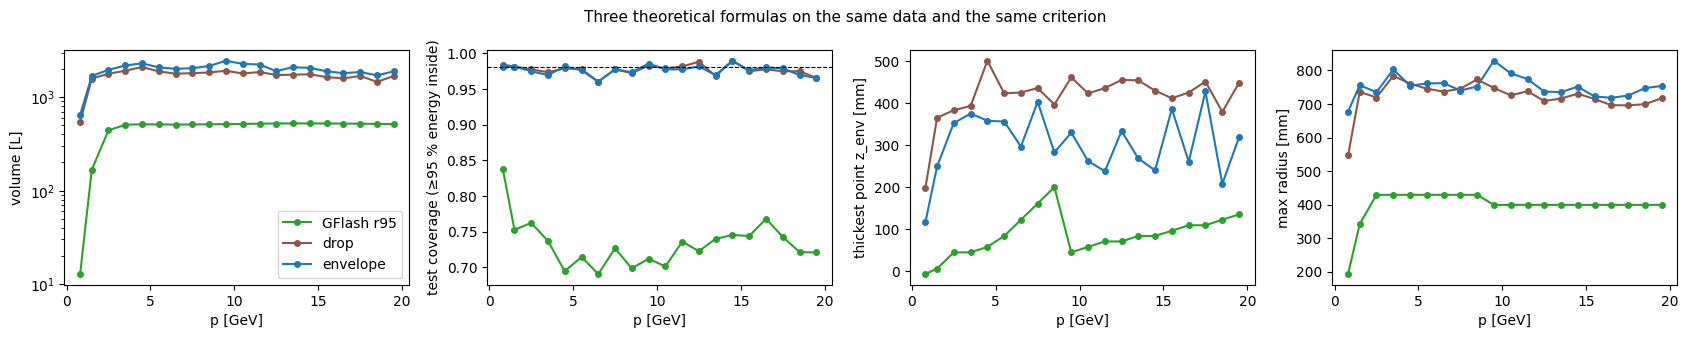

In [10]:
colors = {"GFlash r95": "tab:green", "envelope": "tab:blue", "drop": "tab:brown"}
fig, ax = plt.subplots(1, 4, figsize=(17, 3.4))
for name, g in CMP.groupby("formula"):
    for a_, col in zip(ax, ["V_L", "cov_test", "z_env", "r_max"]):
        a_.plot(g.p_mean, g[col], "o-", c=colors[name], label=name, ms=4)
for a_, lab in zip(ax, ["volume [L]", "test coverage (≥95 % energy inside)", "thickest point z_env [mm]", "max radius [mm]"]):
    a_.set(xlabel="p [GeV]", ylabel=lab)
ax[0].set_yscale("log"); ax[1].axhline(F_EV, c="k", lw=0.8, ls="--"); ax[0].legend()
fig.suptitle("Three theoretical formulas on the same data and the same criterion", fontsize=11)
plt.tight_layout(); plt.show()

### 2D map with $(z', r)$ axes, in the same form as the GFlash `shape_map` and the 02 `envelope_map` plots

- **Background:** mean energy density of the training data in the given 1 GeV bin ($\log_{10}$, $r$ mirrored).
- **Green dotted:** GFlash $r_{95}(z')$ (average shower). **Blue:** the 02 envelope. **Brown:** the drop (bin fit),
  **orange dashed:** the smoothed ($\ln p$ polynomial) drop.

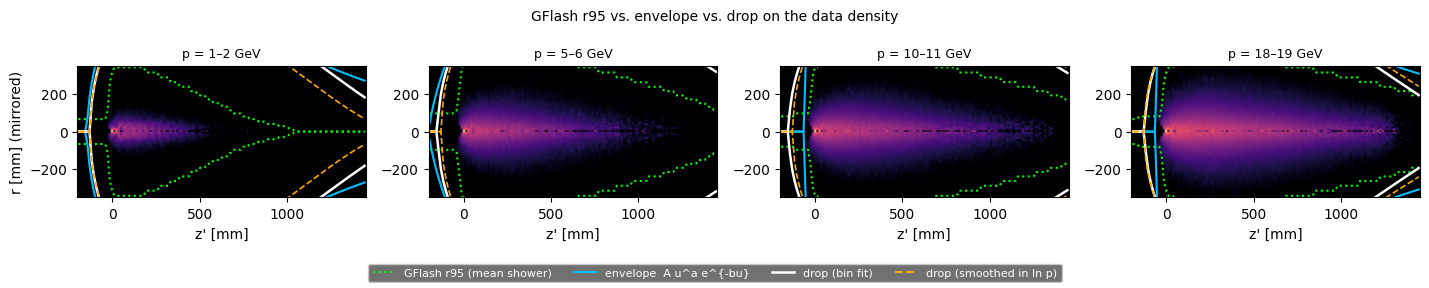

In [11]:
def compare_map(sh, p_values=(1, 5, 10, 18), r_show=350, title=""):
    rc_ = RC.cpu().numpy()
    vol = np.exp(LOG_VOL.cpu().numpy())
    h = sh.hits()
    rs = np.linspace(-r_show, r_show, 121)
    fig, axes = plt.subplots(1, len(p_values), figsize=(3.6 * len(p_values), 2.8))
    for ax, p in zip(axes, p_values):
        b = int(p)
        m = (h.p >= b) & (h.p < b + 1)
        H, _, _ = np.histogram2d(h.z[m], h.r[m], bins=[z_edges, R_EDGES.cpu().numpy()], weights=h.w[m])
        d = H / max(h.ev[m].nunique(), 1) / vol
        img = np.log10(np.clip(np.stack([np.interp(np.abs(rs), rc_, row) for row in d], 1), 1e-14, None))
        ax.imshow(img, origin="lower", aspect="auto", extent=[Z_MIN, Z_MAX, -r_show, r_show], cmap="magma",
                  vmin=img.max() - 5, vmax=img.max())
        curves = []
        if GF is not None:
            curves.append((gflash_r95(b + 0.5), dict(c="lime", ls=":", lw=1.5)))
        if b in ENV:
            curves.append((envelope_r(zc, ENV[b]), dict(c="deepskyblue", lw=1.5)))
        if b in DROP:
            curves.append((drop_radius(zc, DROP[b]), dict(c="white", lw=1.8)))
            curves.append((drop_radius(zc, smooth_drop(DROP[b]["p_mean"])), dict(c="orange", ls="--", lw=1.2)))
        for r, kw in curves:
            ax.plot(zc, r, **kw); ax.plot(zc, -r, **kw)
        ax.set_ylim(-r_show, r_show); ax.set_title(f"p = {b}–{b + 1} GeV", fontsize=9); ax.set_xlabel("z' [mm]")
    axes[0].set_ylabel("r [mm] (mirrored)")
    handles = [plt.Line2D([], [], c="lime", ls=":", label="GFlash r95 (mean shower)"),
               plt.Line2D([], [], c="deepskyblue", label="envelope  A u^a e^{-bu}"),
               plt.Line2D([], [], c="white", lw=1.8, label="drop (bin fit)"),
               plt.Line2D([], [], c="orange", ls="--", label="drop (smoothed in ln p)")]
    fig.legend(handles=handles, loc="lower center", ncol=4, fontsize=8, facecolor="0.3", labelcolor="w")
    fig.suptitle(title, fontsize=10)
    fig.tight_layout(rect=(0, 0.1, 1, 1))
    plt.show()


compare_map(data["train"], title="GFlash r95 vs. envelope vs. drop on the data density")

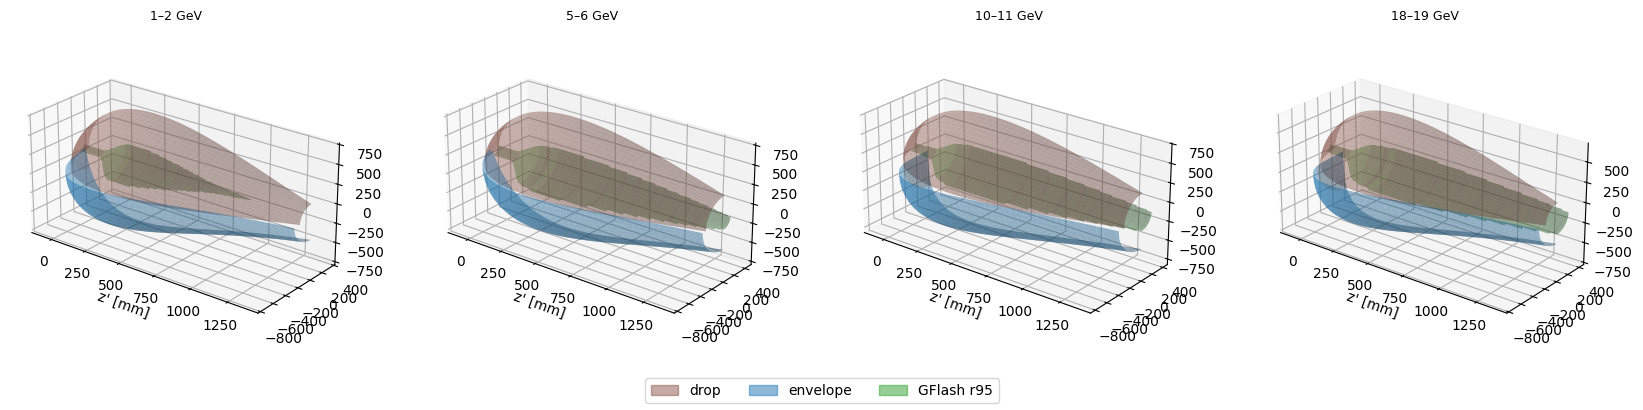

In [12]:
# the three bodies side by side in 3D for a few bins
show = [b for b in (1, 5, 10, 18) if b in DROP]
fig = plt.figure(figsize=(4.2 * len(show), 4))
for j, b in enumerate(show):
    ax_ = fig.add_subplot(1, len(show), j + 1, projection="3d")
    bodies = [("drop", drop_radius(zc, DROP[b]), "tab:brown", (0.5 * np.pi, 1.0 * np.pi))]
    if b in ENV:
        bodies.append(("envelope", envelope_r(zc, ENV[b]), "tab:blue", (1.0 * np.pi, 1.5 * np.pi)))
    if GF is not None:
        bodies.append(("GFlash r95", gflash_r95(b + 0.5), "tab:green", (1.5 * np.pi, 2.0 * np.pi)))
    for name, r, c, (f0, f1) in bodies:                  # each body in its own quarter, so all three stay visible
        ax_.plot_surface(*revolve(zc, r, f0, f1, 18), color=c, alpha=0.45, linewidth=0)
    ax_.set_xlim(-150, 1450); ax_.set_box_aspect((2.2, 1, 1)); ax_.view_init(elev=24, azim=-52)
    ax_.set_title(f"{b}–{b + 1} GeV", fontsize=9); ax_.set_xlabel("z' [mm]")
fig.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c, alpha=0.5, label=n)
                    for n, c in [("drop", "tab:brown"), ("envelope", "tab:blue"), ("GFlash r95", "tab:green")]],
           loc="lower center", ncol=3)
plt.tight_layout(rect=(0, 0.08, 1, 1)); plt.show()
CMP.to_csv(f"{OUT_DIR}/proton/comparison_3formulas.csv", index=False)